检查当前目录和文件

In [1]:
!pwd
!ls -lh

/home/ec2-user/SageMaker/zh_cn/CDC_DCDC_Diabetes_Project
total 500K
-rw-rw-r-- 1 ec2-user ec2-user 286K Feb 10 17:08 correlation_analysis.png
drwxrwxr-x 2 ec2-user ec2-user 4.0K Feb 10 16:37 data
-rw-rw-r-- 1 ec2-user ec2-user 200K Feb 10 17:14 FAIDM.ipynb
-rw-rw-r-- 1 ec2-user ec2-user 1.4K Feb 10 16:50 feature_correlations.csv
drwxrwxr-x 2 ec2-user ec2-user 4.0K Feb 10 16:38 outputs


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings('ignore')

print("=" * 80)
print("CDC DIABETES DATASET - CORRELATION ANALYSIS")
print("=" * 80)

# 检查当前目录
print(f"\n当前工作目录: {os.getcwd()}")
print("\n当前目录的文件:")
print("-" * 80)
for f in os.listdir('.')[:20]:  # 只显示前20个文件
    print(f"  {f}")


CDC DIABETES DATASET - CORRELATION ANALYSIS

当前工作目录: /home/ec2-user/SageMaker/zh_cn/CDC_DCDC_Diabetes_Project

当前目录的文件:
--------------------------------------------------------------------------------
  FAIDM.ipynb
  outputs
  data
  .ipynb_checkpoints
  feature_correlations.csv
  correlation_analysis.png


加载数据

In [3]:
print("\n" + "=" * 80)
print("1. 加载数据")
print("=" * 80)

# 方式1: 如果CSV文件在当前目录
data_file = 'data/CDC Diabetes Dataset.csv'


try:
    df = pd.read_csv(data_file)
    print(f"✓ 数据加载成功!")
    print(f"  样本数: {len(df):,}")
    print(f"  特征数: {df.shape[1]}")
    print(f"  缺失值: {df.isnull().sum().sum()}")
except FileNotFoundError:
    print(f"❌ 错误: 找不到文件 '{data_file}'")
    print("\n可用的文件:")
    for f in os.listdir('.'):
        if f.endswith('.csv'):
            print(f"  - {f}")
    raise

print("\n特征列表:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col}")


1. 加载数据
✓ 数据加载成功!
  样本数: 253,680
  特征数: 22
  缺失值: 0

特征列表:
   1. Diabetes_012
   2. HighBP
   3. HighChol
   4. CholCheck
   5. BMI
   6. Smoker
   7. Stroke
   8. HeartDiseaseorAttack
   9. PhysActivity
  10. Fruits
  11. Veggies
  12. HvyAlcoholConsump
  13. AnyHealthcare
  14. NoDocbcCost
  15. GenHlth
  16. MentHlth
  17. PhysHlth
  18. DiffWalk
  19. Sex
  20. Age
  21. Education
  22. Income


In [4]:
df.shape

(253680, 22)

现在，您将获取列的列表。

In [5]:
df.columns

Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='object')

您有哪些列类型

In [6]:
df.dtypes

Diabetes_012            float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

要查看第一列的统计数据，可以使用 describe 函数。

In [7]:
df['Diabetes_012'].describe()

count    253680.000000
mean          0.296921
std           0.698160
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           2.000000
Name: Diabetes_012, dtype: float64

对整个 DataFrame 运行 **describe** 来显示每个特征的统计数据。

In [8]:
df.describe()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.296921,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.698160,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,2.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


**问题**：是否存在分布不均衡的特征？ 是否存在您想要查看的具有离群值的特征？ 看起来特征之间存在相关性吗？

仅查看数字时，观察并不总是那么容易，因此现在您将给这些值绘图。

<Axes: >

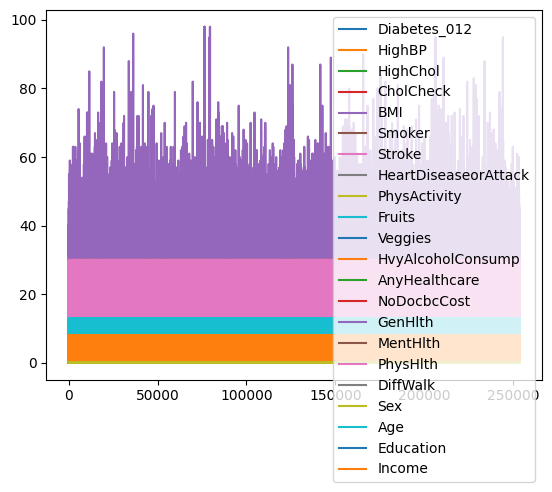

In [9]:
import matplotlib.pyplot as plt
%matplotlib inline
df.plot()

现在，您将使用*密度或核密度估计(KDE)图来绘制每个特征的值分布。

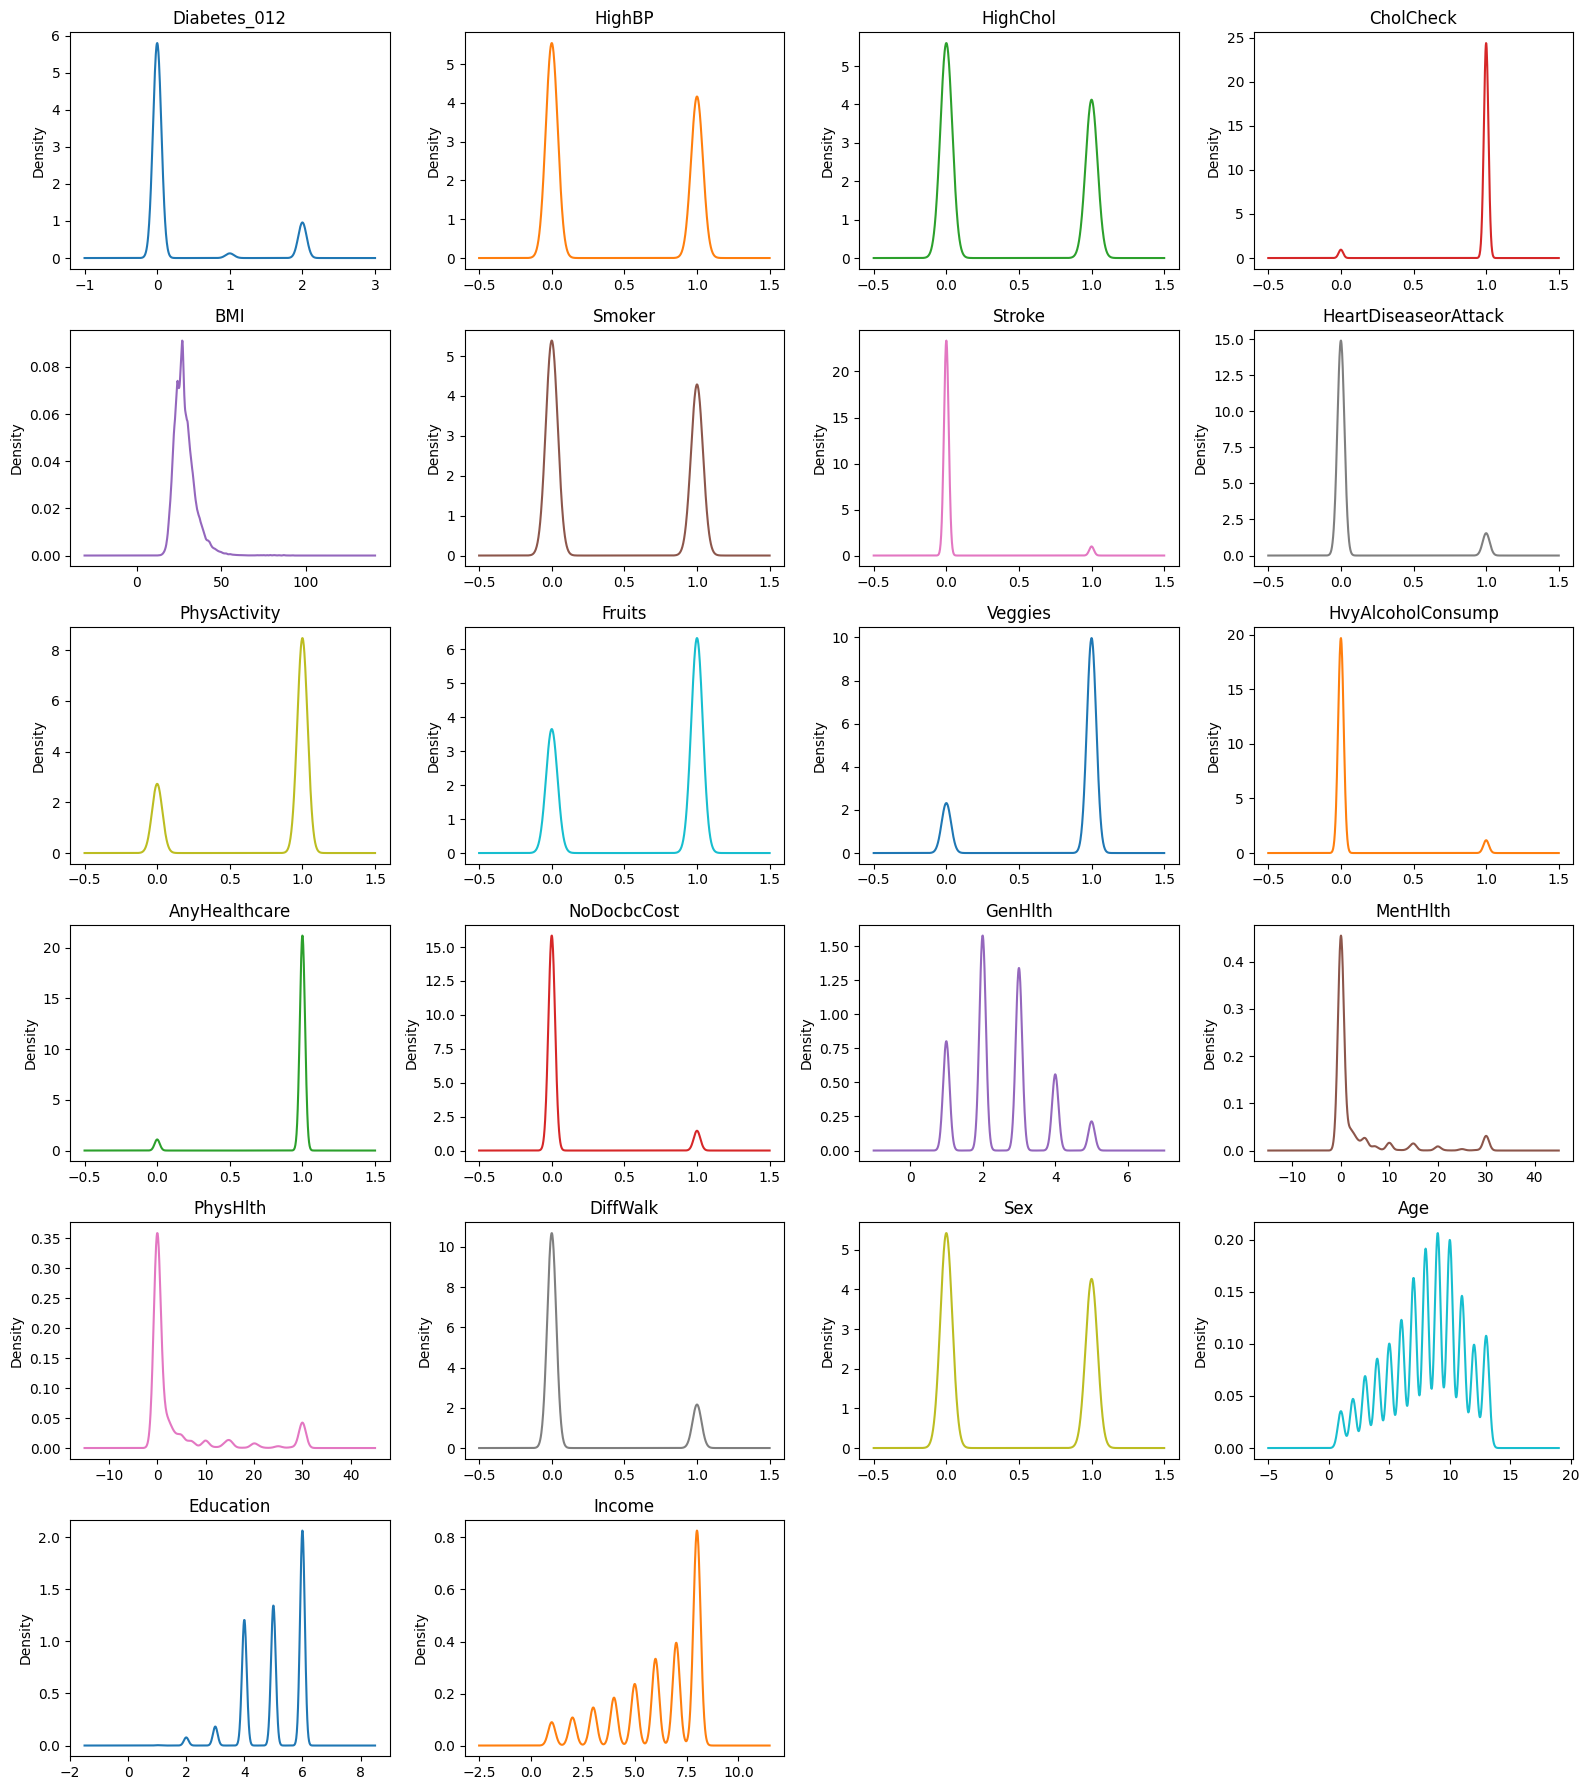

In [14]:
axes = df.plot(kind='density',subplots=True,layout=(6,4),figsize=(16,18),sharex=False, legend=False, title=list(df.columns))
plt.tight_layout()
plt.show()

计算相关性矩阵

In [11]:
print("\n" + "=" * 80)
print("2. 相关性矩阵计算")
print("=" * 80)

corr_matrix = df.corr()
print(f"\n相关性矩阵大小: {corr_matrix.shape}")


2. 相关性矩阵计算

相关性矩阵大小: (22, 22)


与目标变量的相关性（完整排序）

In [13]:
print("\n" + "=" * 80)
print("3. 与 Diabetes_012 的相关性分析")
print("=" * 80)

# 获取完整的相关性（按实际值排序，非绝对值）
target_corr = corr_matrix["Diabetes_012"].sort_values(ascending=False)

print("\n完整相关性排序 (ALL FEATURES):")
print("-" * 80)
for i, (feat, corr_val) in enumerate(target_corr.items(), 1):
    if feat != 'Diabetes_012':
        direction = "Positive (Risk Factor)" if corr_val > 0 else "Negative (Protective Factor)"
        strength = "Strong" if abs(corr_val) > 0.2 else "Moderate" if abs(corr_val) > 0.1 else "Weak"
        print(f"  {i:2d}. {feat:25s}: r = {corr_val:7.4f}  [{strength:8s}, {direction}]")


3. 与 Diabetes_012 的相关性分析

完整相关性排序 (ALL FEATURES):
--------------------------------------------------------------------------------
   2. GenHlth                  : r =  0.3026  [Strong  , Positive (Risk Factor)]
   3. HighBP                   : r =  0.2716  [Strong  , Positive (Risk Factor)]
   4. BMI                      : r =  0.2244  [Strong  , Positive (Risk Factor)]
   5. DiffWalk                 : r =  0.2242  [Strong  , Positive (Risk Factor)]
   6. HighChol                 : r =  0.2091  [Strong  , Positive (Risk Factor)]
   7. Age                      : r =  0.1850  [Moderate, Positive (Risk Factor)]
   8. HeartDiseaseorAttack     : r =  0.1803  [Moderate, Positive (Risk Factor)]
   9. PhysHlth                 : r =  0.1763  [Moderate, Positive (Risk Factor)]
  10. Stroke                   : r =  0.1072  [Moderate, Positive (Risk Factor)]
  11. MentHlth                 : r =  0.0735  [Weak    , Positive (Risk Factor)]
  12. CholCheck                : r =  0.0675  [Weak    , P

保存结果到 DataFrame

In [6]:
print("\n" + "=" * 80)
print("4. 保存相关性数据")
print("=" * 80)

# 创建 DataFrame
correlation_df = pd.DataFrame({
    'Feature': target_corr.index,
    'Correlation': target_corr.values,
    'Abs_Correlation': target_corr.abs().values,
    'Direction': ['Risk' if x > 0 else 'Protective' for x in target_corr.values],
    'Strength': ['Strong' if abs(x) > 0.2 else 'Moderate' if abs(x) > 0.1 else 'Weak' 
                 for x in target_corr.values]
}).query('Feature != "Diabetes_012"')

# 保存到CSV
correlation_df.to_csv('feature_correlations.csv', index=False)
print("✓ 已保存: feature_correlations.csv")

# 显示数据
print("\n前10个特征:")
print(correlation_df.head(10).to_string(index=False))



4. 保存相关性数据
✓ 已保存: feature_correlations.csv

前10个特征:
             Feature  Correlation  Abs_Correlation Direction Strength
             GenHlth     0.302587         0.302587      Risk   Strong
              HighBP     0.271596         0.271596      Risk   Strong
                 BMI     0.224379         0.224379      Risk   Strong
            DiffWalk     0.224239         0.224239      Risk   Strong
            HighChol     0.209085         0.209085      Risk   Strong
                 Age     0.185026         0.185026      Risk Moderate
HeartDiseaseorAttack     0.180272         0.180272      Risk Moderate
            PhysHlth     0.176287         0.176287      Risk Moderate
              Stroke     0.107179         0.107179      Risk Moderate
            MentHlth     0.073507         0.073507      Risk     Weak


In [ ]:
**问题**：是否存在分布不均衡的特征？ 是否存在您想要查看的具有离群值的特征？ 看起来特征之间存在相关性吗？

Visualization


5. 可视化分析
✓ 已保存: correlation_analysis.png


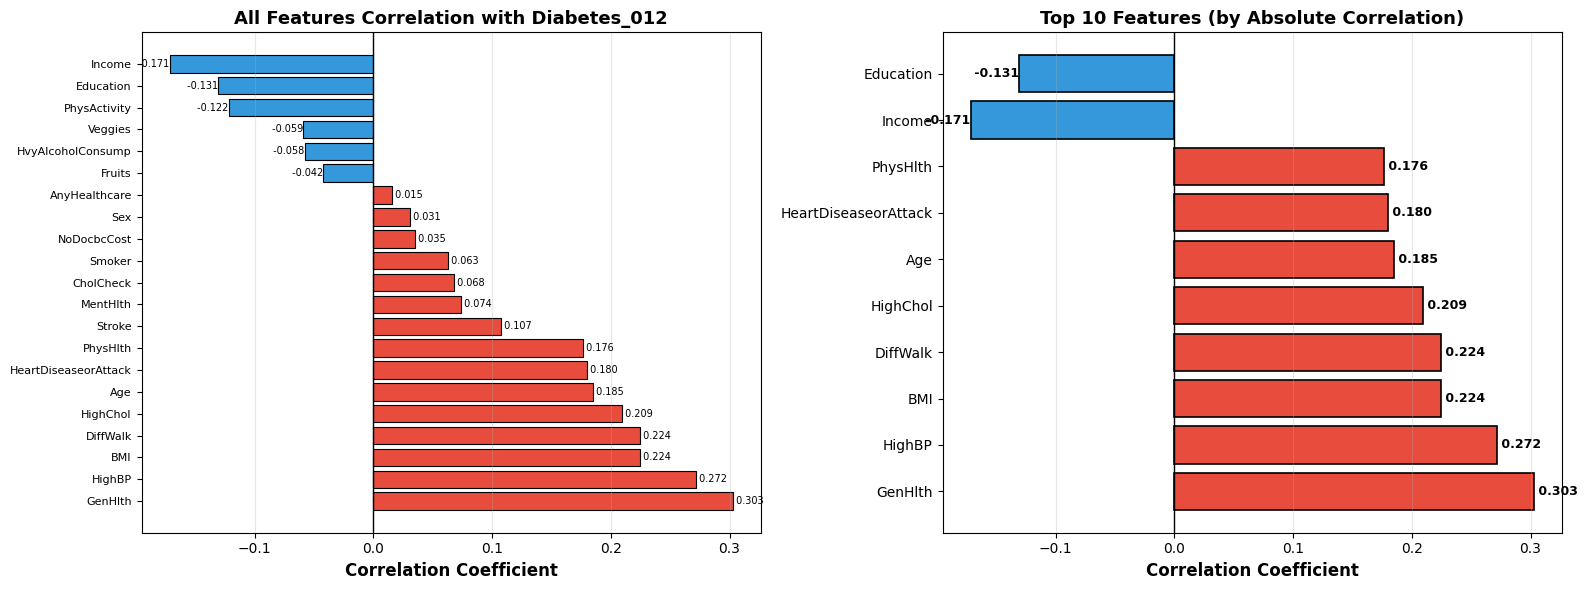

In [13]:
print("\n" + "=" * 80)
print("5. 可视化分析")
print("=" * 80)

# Top 10 features (按绝对值)
top_features = correlation_df.nlargest(10, 'Abs_Correlation')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: 所有特征的相关性（按实际值排序）
ax1 = axes[0]
colors1 = ['#e74c3c' if x > 0 else '#3498db' for x in correlation_df['Correlation']]
ax1.barh(range(len(correlation_df)), correlation_df['Correlation'], color=colors1, edgecolor='black', linewidth=0.8)
ax1.set_yticks(range(len(correlation_df)))
ax1.set_yticklabels(correlation_df['Feature'], fontsize=8)
ax1.set_xlabel('Correlation Coefficient', fontweight='bold', fontsize=12)
ax1.set_title('All Features Correlation with Diabetes_012', fontweight='bold', fontsize=13)
ax1.axvline(0, color='black', linewidth=1)
ax1.grid(axis='x', alpha=0.3)

# 添加标签
for i, val in enumerate(correlation_df['Correlation']):
    ax1.text(val, i, f' {val:.3f}', va='center', fontsize=7, 
            ha='left' if val > 0 else 'right')

# Plot 2: Top 10 特征（按绝对值）
ax2 = axes[1]
colors2 = ['#e74c3c' if x > 0 else '#3498db' for x in top_features['Correlation']]
bars = ax2.barh(range(len(top_features)), top_features['Correlation'], color=colors2, 
               edgecolor='black', linewidth=1.2)
ax2.set_yticks(range(len(top_features)))
ax2.set_yticklabels(top_features['Feature'], fontsize=10)
ax2.set_xlabel('Correlation Coefficient', fontweight='bold', fontsize=12)
ax2.set_title('Top 10 Features (by Absolute Correlation)', fontweight='bold', fontsize=13)
ax2.axvline(0, color='black', linewidth=1)
ax2.grid(axis='x', alpha=0.3)

# 添加数值标签
for i, (bar, val) in enumerate(zip(bars, top_features['Correlation'])):
    ax2.text(val, i, f' {val:.3f}', va='center', fontweight='bold', fontsize=9,
            ha='left' if val > 0 else 'right')

plt.tight_layout()
plt.savefig('correlation_analysis.png', dpi=300, bbox_inches='tight')
print("✓ 已保存: correlation_analysis.png")
plt.show()